# Project job scheduling

A builder runs several construction projects at once and all of them draw on one workforce. Each
project is a chain of jobs: foundations before the frame, the frame before the roof. Each job can run
at a normal pace, or be rushed by paying from that project's limited budget. The question is **when
does each job start, and at which pace**, so that the workforce is never overbooked and the projects
finish as close as possible to their targets.

In this notebook you will:

1. describe projects, jobs and resources as Python objects,
2. solve it and draw a Gantt chart per project with the workforce profile below it,
3. check the result yourself, without trusting the solver's score,
4. change the rules so that overtime is allowed at a price,
5. change the workforce and see how delay responds,
6. restart from an existing plan, and add a project while one client's dates stay fixed.

Requires Python 3.11+: `pip install optimaru matplotlib`

In [1]:
from itertools import product

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator

from optimaru import project_job_scheduling as pj
from optimaru.project_job_scheduling import constraints as rules
from optimaru.project_job_scheduling.models import (
    AllocationModel, ExecutionModeModel, JobModel, ProjectJobScheduleModel, ProjectModel, ResourceModel,
    ResourceRequirementModel,
)

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, MUTED = "#52514e", "#898781"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": MUTED, "ytick.color": MUTED,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "legend.frameon": False, "font.size": 10,
})

## 1. Describe the projects

Time is in whole days from day 0. These objects make up a schedule:

| Object | What it holds |
| --- | --- |
| `ProjectModel` | a release date and a critical path length, which together set the target finish |
| `ResourceModel` | a capacity. Renewable resources reset each day, others are a stock for the whole plan |
| `JobModel` | the job's execution modes and the ids of the jobs that must wait for it |
| `ExecutionModeModel` | one way to do a job: a duration and what it needs from each resource |
| `AllocationModel` | one per job. **The solver fills in `execution_mode_id` and `delay`.** |

Every project has a `SOURCE` and a `SINK`: zero-length milestones that mark its start and end.

`delay` counts from the moment a job's predecessors are done, so a start date is always relative. The
solver's result includes the actual `start_date` and `end_date`.

All of this builder's projects follow the same plan, and the durations and crew sizes are invented
per project. A rushed job takes about 60% of the days, needs one more worker, and spends budget.

In [2]:
PROJECTS = ["Library", "Bus depot", "Clinic", "Fire station"]
STAGES = {  # stage: stages it must wait for
    "Survey": [], "Foundation": ["Survey"], "Frame": ["Foundation"], "Roof": ["Frame"],
    "Wiring": ["Frame"], "Plumbing": ["Frame"], "Finishing": ["Roof", "Wiring", "Plumbing"],
}
CREW, BUDGET = 8, 6

rng = np.random.default_rng(4)
JOB_DATA = {
    project: {
        stage: {"days": int(days), "crew": int(crew), "rush_cost": int(rush_cost)}
        for stage, days, crew, rush_cost in zip(
            STAGES, rng.integers(3, 9, len(STAGES)), rng.integers(2, 5, len(STAGES)),
            rng.integers(1, 4, len(STAGES)),
        )
    }
    for project in PROJECTS
}


def rushed_days(days):
    return max(1, round(days * 0.6))


def critical_path(project):
    """The shortest possible project length: the longest chain of stages, every job rushed."""
    finish = {}
    for stage, before in STAGES.items():
        days = rushed_days(JOB_DATA[project][stage]["days"])
        finish[stage] = max((finish[b] for b in before), default=0) + days
    return max(finish.values())


def stage_job(project, stage, data):
    needs = lambda crew, *extra: [ResourceRequirementModel(resource_id="Crew", requirement=crew), *extra]
    spend = ResourceRequirementModel(resource_id=f"{project} budget", requirement=data["rush_cost"])
    waiting = [f"{project} {later}" for later, before in STAGES.items() if stage in before]
    return JobModel(
        id=f"{project} {stage}", project_id=project,
        execution_modes=[
            ExecutionModeModel(id="normal", duration=data["days"], resource_requirements=needs(data["crew"])),
            ExecutionModeModel(id="rushed", duration=rushed_days(data["days"]),
                               resource_requirements=needs(data["crew"] + 1, spend)),
        ],
        successor_job_ids=waiting or [f"{project} end"],
    )


def make_schedule(crew=CREW, projects=PROJECTS[:3]):
    """A fresh, unsolved schedule."""
    jobs = []
    for project in projects:
        jobs.append(JobModel(id=f"{project} start", project_id=project, job_type="SOURCE",
                             execution_modes=[ExecutionModeModel(id="milestone")],
                             successor_job_ids=[f"{project} Survey"]))
        jobs += [stage_job(project, stage, data) for stage, data in JOB_DATA[project].items()]
        jobs.append(JobModel(id=f"{project} end", project_id=project, job_type="SINK",
                             execution_modes=[ExecutionModeModel(id="milestone")]))
    return ProjectJobScheduleModel(
        projects=[ProjectModel(id=p, release_date=5 * PROJECTS.index(p),
                               critical_path_duration=critical_path(p)) for p in projects],
        resources=[ResourceModel(id="Crew", capacity=crew),
                   *(ResourceModel(id=f"{p} budget", capacity=BUDGET, renewable=False, project_id=p)
                     for p in projects)],
        jobs=jobs,
        allocations=[AllocationModel(id=job.id, job_id=job.id) for job in jobs],
        delay_range_size=60,
    )


problem = make_schedule()
print(f"{len(problem.projects)} projects, {len(problem.jobs)} jobs including milestones")
for project in problem.projects:
    print(f"{project.id:10} released day {project.release_date:2}, "
          f"critical path {project.critical_path_duration:2} days, "
          f"target finish day {project.release_date + project.critical_path_duration}")

3 projects, 27 jobs including milestones
Library    released day  0, critical path 24 days, target finish day 24
Bus depot  released day  5, critical path 19 days, target finish day 24
Clinic     released day 10, critical path 18 days, target finish day 28


Two things in that table are often misread.

- `critical_path_duration` is your input, not something the solver computes. Here it assumes every job
  is rushed and the workforce is unlimited, so a target is a very tight bound.
- `release_date` only sets the target. It does **not** stop a project starting early, because no rule
  uses it for that.

Each project follows this order, and a job can start only after every arrow into it is done.

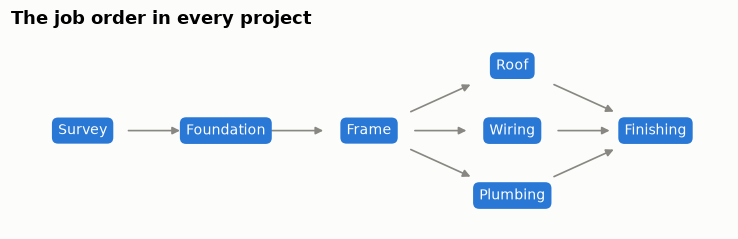

In [3]:
POSITION = {"Survey": (0, 0), "Foundation": (1, 0), "Frame": (2, 0), "Roof": (3, 1), "Wiring": (3, 0),
            "Plumbing": (3, -1), "Finishing": (4, 0)}

fig, ax = plt.subplots(figsize=(8.4, 2.3))
for stage, before in STAGES.items():
    for earlier in before:
        ax.annotate("", xy=POSITION[stage], xytext=POSITION[earlier], zorder=1,
                    arrowprops=dict(arrowstyle="-|>", color=MUTED, linewidth=1.1, shrinkA=30, shrinkB=30))
for stage, (x, y) in POSITION.items():
    ax.text(x, y, stage, ha="center", va="center", color="white", fontsize=9, zorder=2,
            bbox=dict(boxstyle="round,pad=0.45", facecolor=COLORS[0], edgecolor="none"))
ax.set(xlim=(-0.5, 4.5), ylim=(-1.5, 1.5))
ax.axis("off")
ax.set_title("The job order in every project", loc="left")
plt.show()

## 2. Solve it

`pj.solve` takes the model and returns a solved copy. The score has three levels, compared in order:

- **hard**: resource overuse, where `0` means the plan can be carried out. A renewable resource counts
  the excess on each day, and a stock counts the excess over the whole plan.
- **medium**: minus the total project delay, in days. A project's delay is how far its `SINK` ends
  after release date plus critical path. Finishing early earns nothing.
- **soft**: minus the makespan, the day the last project finishes.

In [4]:
def score_of(solution):
    return solution.score_hard, solution.score_medium, solution.score_soft


def best_of(schedule, seconds=0.5, seeds=range(6), **options):
    """One search per seed, keeping the best plan."""
    runs = [pj.solve(schedule, time_limit_seconds=seconds, random_seed=seed, **options) for seed in seeds]
    return max(runs, key=score_of), [-run.score_medium for run in runs]


construction = pj.solve(make_schedule(), time_limit_seconds=0, random_seed=0)
plan, delays_by_seed = best_of(make_schedule())

print("construction only:", score_of(construction))
print("delay by seed    :", delays_by_seed)
print("feasible         :", plan.score_hard == 0)
print("best score       :", score_of(plan))

construction only: (0, -47, -54)
delay by seed    : [46, 47, 40, 47, 47, 47]
feasible         : True
best score       : (0, -40, -52)


With a time limit of `0` the solver stops after its construction heuristic, which is a useful baseline.
Compare the seeds with it. This problem is hard for the search: `delay` is relative, so changing one job
also moves every job after it. Some seeds stay at the construction plan, more time often does not move
them, and others escape early. That is why this notebook runs several short seeds and keeps the best one,
instead of one long run.

### The plan

The top chart has one row per job, in one color per project, and outlined bars are rushed jobs. Thin
lines connect each job to the jobs waiting for it, and the black tick in each project is its target
finish. The bottom chart adds up the crew in use each day against the capacity line.

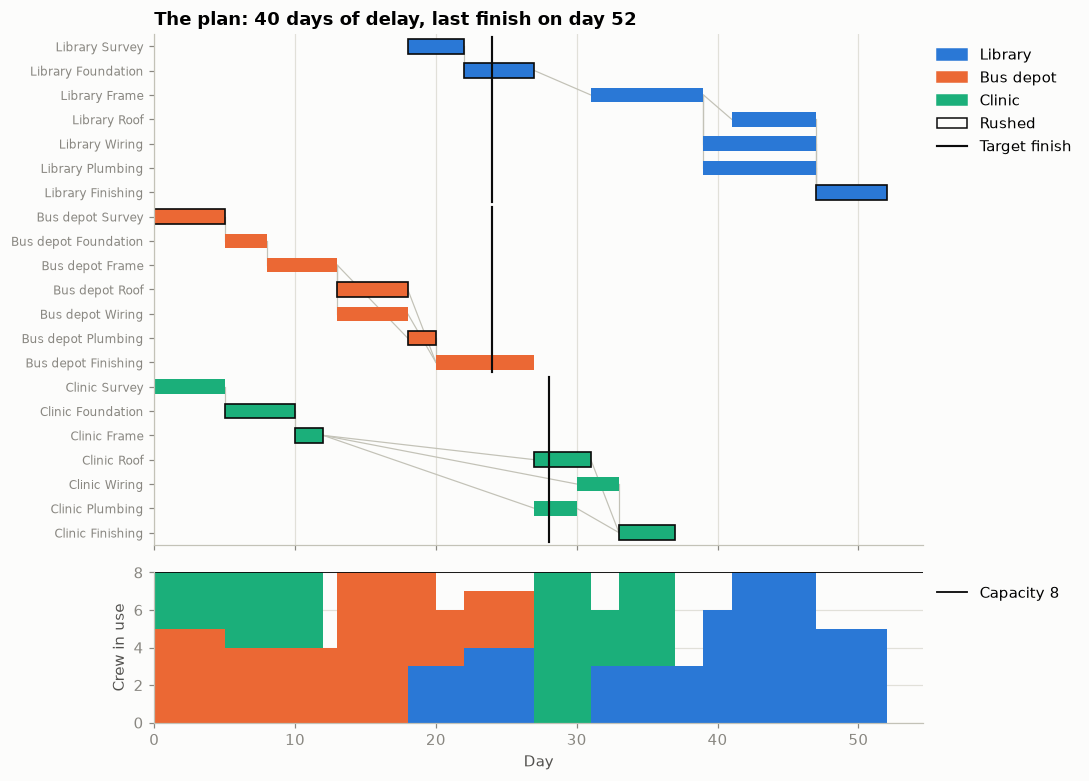

In [5]:
def mode_of(solution, allocation):
    job = next(j for j in solution.jobs if j.id == allocation.job_id)
    return next(m for m in job.execution_modes if m.id == allocation.execution_mode_id)


def demand(mode, resource):
    return sum(r.requirement for r in mode.resource_requirements if r.resource_id == resource)


def working(solution):
    """The solved allocations of real jobs, with the project each belongs to."""
    project_of = {j.id: j.project_id for j in solution.jobs}
    standard = {j.id for j in solution.jobs if j.job_type == "STANDARD"}
    return [(project_of[a.job_id], a) for a in solution.allocations if a.job_id in standard]


def crew_profile(solution):
    """Crew in use: one row per project, one column per day."""
    projects = [p.id for p in solution.projects]
    last = max(a.end_date for a in solution.allocations)
    profile = np.zeros((len(projects), last), dtype=int)
    for project, allocation in working(solution):
        profile[projects.index(project), allocation.start_date:allocation.end_date] += demand(
            mode_of(solution, allocation), "Crew")
    return profile


def project_delays(solution):
    ends = {a.id: a.end_date for a in solution.allocations}
    return {p.id: max(0, ends[f"{p.id} end"] - p.release_date - p.critical_path_duration)
            for p in solution.projects}


def color_of(project):
    return COLORS[PROJECTS.index(project)]


def draw_gantt(ax, solution, outlined=()):
    rows = {a.id: row for row, (_, a) in enumerate(working(solution))}
    dates = {a.id: a for a in solution.allocations}
    for job in solution.jobs:
        for later in job.successor_job_ids:
            if job.id in rows and later in rows:
                ax.plot([dates[job.id].end_date, dates[later].start_date], [rows[job.id], rows[later]],
                        color="#c3c2b7", linewidth=0.8, zorder=1)
    for project, allocation in working(solution):
        rushed = allocation.execution_mode_id == "rushed"
        ax.barh(rows[allocation.id], allocation.end_date - allocation.start_date, left=allocation.start_date,
                height=0.6, color=color_of(project), zorder=2, linewidth=1.1,
                edgecolor="#0b0b0b" if rushed or allocation.id in outlined else "none")
    for p in solution.projects:
        project_rows = [rows[a.id] for project, a in working(solution) if project == p.id]
        target = p.release_date + p.critical_path_duration
        ax.plot([target, target], [min(project_rows) - 0.4, max(project_rows) + 0.4], color="#0b0b0b",
                linewidth=1.4, zorder=3)
    ax.set_yticks(list(rows.values()), list(rows), fontsize=8)
    ax.set_ylim(len(rows) - 0.5, -0.5)
    ax.grid(True, axis="x")


def draw_profile(ax, solution, capacity):
    profile = crew_profile(solution)
    days = np.arange(profile.shape[1])
    bottom = np.zeros(len(days))
    for row, project in zip(profile, solution.projects):
        ax.bar(days + 0.5, row, width=1, bottom=bottom, color=color_of(project.id), linewidth=0)
        bottom += row
    ax.axhline(capacity, color="#0b0b0b", linewidth=1.2)
    ax.grid(True, axis="y")


def project_handles(solution):
    return [Patch(color=color_of(p.id), label=p.id) for p in solution.projects]


fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 7.2), sharex=True,
                                  gridspec_kw={"height_ratios": [3.4, 1]})
draw_gantt(top, plan)
draw_profile(bottom, plan, CREW)
top.set_title(f"The plan: {-plan.score_medium} days of delay, last finish on day {-plan.score_soft}")
bottom.set(xlabel="Day", ylabel="Crew in use")
top.legend(handles=[*project_handles(plan), Patch(facecolor="none", edgecolor="#0b0b0b", label="Rushed"),
                    Line2D([], [], color="#0b0b0b", linewidth=1.4, label="Target finish")],
           loc="upper left", bbox_to_anchor=(1, 1))
bottom.legend(handles=[Line2D([], [], color="#0b0b0b", linewidth=1.2, label=f"Capacity {CREW}")],
              loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

## 3. Check the result yourself

The solved model holds each job's dates and mode, so every rule can be recomputed from them with no
solver code: the order of jobs, the crew on each day, the budget spent, and the two objective levels.

In [6]:
def audit(solution, capacity):
    """Rule counts recomputed from the output alone."""
    dates = {a.id: a for a in solution.allocations}
    order_breaks = sum(dates[job.id].end_date > dates[later].start_date
                       for job in solution.jobs for later in job.successor_job_ids)
    used = crew_profile(solution).sum(axis=0)
    spend = {r.id: sum(demand(mode_of(solution, a), r.id) for _, a in working(solution))
             for r in solution.resources if not r.renewable}
    over_budget = sum(max(0, spend[r.id] - r.capacity) for r in solution.resources if not r.renewable)
    return {"order breaks": order_breaks, "crew overuse": int(np.maximum(used - capacity, 0).sum()),
            "over budget": over_budget, "delay": sum(project_delays(solution).values()),
            "makespan": max(a.end_date for a in solution.allocations), "spend": spend}


check = audit(plan, CREW)
print("jobs starting before their predecessors end:", check["order breaks"])
print("crew days over capacity                    :", check["crew overuse"])
print("budget units over the limit                :", check["over budget"])
print(f"total delay {check['delay']}, solver says {-plan.score_medium}")
print(f"makespan {check['makespan']}, solver says {-plan.score_soft}")
print("delay by project:", project_delays(plan))
print("budget spent    :", check["spend"], f"of {BUDGET} each")

release = {p.id: p.release_date for p in plan.projects}
print("jobs starting before release:", sum(a.start_date < release[p] for p, a in working(plan)))

jobs starting before their predecessors end: 0
crew days over capacity                    : 0
budget units over the limit                : 0
total delay 40, solver says 40
makespan 52, solver says 52
delay by project: {'Library': 28, 'Bus depot': 3, 'Clinic': 9}
budget spent    : {'Library budget': 5, 'Bus depot budget': 6, 'Clinic budget': 6} of 6 each
jobs starting before release: 3


## 4. Change the rules, not the solver

Every rule is a plugin. `list_constraints()` shows what ships with this use case, and passing
`constraints=` to `pj.solve` replaces the set. Only listed rules are scored.

In [7]:
for name in pj.list_constraints():
    print(name)

non_renewable_resource_capacity
renewable_resource_capacity
total_project_delay
total_makespan


`weight` scales a rule and `hard` moves it between levels. Leave `TotalProjectDelay` at its default
level: it sits on the medium level, and `hard=False` would fold it into soft.

So far the crew limit is absolute. A real builder can pay for overtime. Making
`RenewableResourceCapacity` soft lets the plan run over the line at a price. A day of project delay
weighs `10^9` inside the solver, so `weight=2e8` says five crew days of overtime cost as much as one day
of delay.

With this change the score stops meaning what it did. The overtime cost is folded into the medium and
soft numbers, so `score_medium` is no longer the delay. Read delay and overtime from the plan instead.

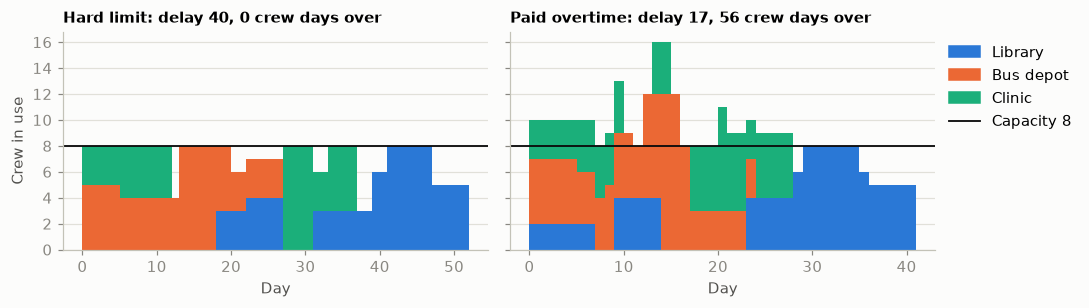

hard limit   : {'order breaks': 0, 'crew overuse': 0, 'over budget': 0, 'delay': 40, 'makespan': 52}
paid overtime: {'order breaks': 0, 'crew overuse': 56, 'over budget': 0, 'delay': 17, 'makespan': 41}


In [8]:
OVERTIME_PRICE = 2e8
overtime_rules = rules.get_constraints([
    rules.non_renewable_resource_capacity,
    rules.RenewableResourceCapacity(weight=OVERTIME_PRICE, hard=False),
    rules.total_project_delay,
    rules.total_makespan,
])
with_overtime, _ = best_of(make_schedule(), constraints=overtime_rules)

fig, axes = plt.subplots(1, 2, figsize=(10, 2.9), sharey=True)
for ax, solution, label in zip(axes, (plan, with_overtime), ("Hard limit", "Paid overtime")):
    draw_profile(ax, solution, CREW)
    result = audit(solution, CREW)
    ax.set_title(f"{label}: delay {result['delay']}, {result['crew overuse']} crew days over", fontsize=10)
    ax.set_xlabel("Day")
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
axes[0].set_ylabel("Crew in use")
axes[1].legend(handles=[*project_handles(plan),
                        Line2D([], [], color="#0b0b0b", linewidth=1.2, label=f"Capacity {CREW}")],
               loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

print("hard limit   :", {k: v for k, v in audit(plan, CREW).items() if k != "spend"})
print("paid overtime:", {k: v for k, v in audit(with_overtime, CREW).items() if k != "spend"})

Both plans are the best found in these runs rather than proven optima.

## 5. What another worker buys

How much delay comes from the workforce, and how much from the job order and the budget? With unlimited
crew each project is independent, so the smallest possible delay can be found exactly: try every set of
rushed jobs the budget can pay for. That gives a floor no crew size can beat, and this is a proof, not
a search result.

delay floor by project: {'Library': 6, 'Bus depot': 0, 'Clinic': 0}


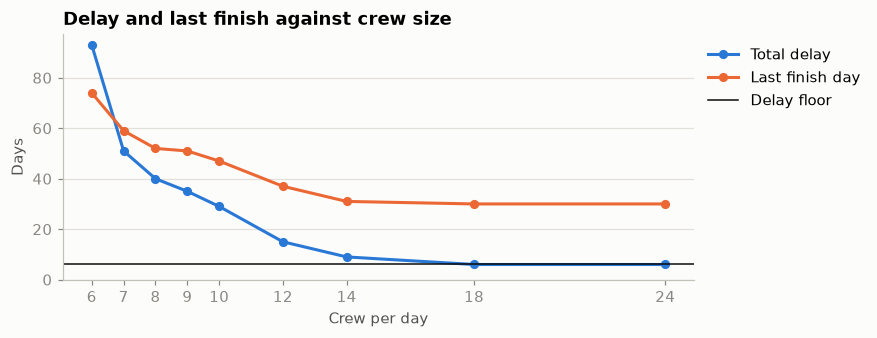

crew  6: hard 0, delay  93, last finish  74, 9 jobs rushed
crew  7: hard 0, delay  51, last finish  59, 9 jobs rushed
crew  8: hard 0, delay  40, last finish  52, 10 jobs rushed
crew  9: hard 0, delay  35, last finish  51, 10 jobs rushed
crew 10: hard 0, delay  29, last finish  47, 11 jobs rushed
crew 12: hard 0, delay  15, last finish  37, 10 jobs rushed
crew 14: hard 0, delay   9, last finish  31, 10 jobs rushed
crew 18: hard 0, delay   6, last finish  30, 10 jobs rushed
crew 24: hard 0, delay   6, last finish  30, 10 jobs rushed


In [9]:
def delay_floor(project):
    """The least delay with unlimited crew: every affordable set of rushed jobs, tried exactly."""
    data, best = JOB_DATA[project], None
    for rushed in product((False, True), repeat=len(STAGES)):
        if sum(data[stage]["rush_cost"] for stage, r in zip(STAGES, rushed) if r) > BUDGET:
            continue
        finish = {}
        for (stage, before), r in zip(STAGES.items(), rushed):
            days = rushed_days(data[stage]["days"]) if r else data[stage]["days"]
            finish[stage] = max((finish[b] for b in before), default=0) + days
        target = 5 * PROJECTS.index(project) + critical_path(project)
        delay = max(0, max(finish.values()) - target)
        best = delay if best is None else min(best, delay)
    return best


floor = {project: delay_floor(project) for project in PROJECTS[:3]}
print("delay floor by project:", floor)

crew_sizes = [6, 7, 8, 9, 10, 12, 14, 18, 24]
by_crew = [best_of(make_schedule(size), seconds=0.25, seeds=range(4))[0] for size in crew_sizes]

fig, ax = plt.subplots(figsize=(7.4, 2.9))
ax.plot(crew_sizes, [-s.score_medium for s in by_crew], color=COLORS[0], linewidth=2, marker="o", markersize=5,
        label="Total delay")
ax.plot(crew_sizes, [-s.score_soft for s in by_crew], color=COLORS[1], linewidth=2, marker="o", markersize=5,
        label="Last finish day")
ax.axhline(sum(floor.values()), color="#0b0b0b", linewidth=1, label="Delay floor")
ax.set(title="Delay and last finish against crew size", xlabel="Crew per day", ylabel="Days", ylim=(0, None))
ax.set_xticks(crew_sizes)
ax.grid(True, axis="y")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

for size, solution in zip(crew_sizes, by_crew):
    rushed = sum(a.execution_mode_id == "rushed" for _, a in working(solution))
    print(f"crew {size:2}: hard {solution.score_hard}, delay {-solution.score_medium:3}, "
          f"last finish {-solution.score_soft:3}, {rushed} jobs rushed")

A target assumes every job is rushed, and a budget cannot pay for that, which is why the floor can be
above zero. Where the blue line meets the floor, more workers buy nothing and only budget could help.
Each point is the best of a few short runs, so a small step the wrong way between two sizes is noise.

## 6. Restart from an existing plan

`with_initial_solution(problem, solution)` returns a copy of `problem` whose search starts from
`solution`. Allocations are matched by id, one the solution leaves out is placed by the construction
heuristic, and a complete solution is exactly where the search starts.

On this problem the search depends on ruin and recreate, which clears several jobs at once. Without it,
no seed below improves on the construction plan.

In [10]:
ROUND_SECONDS = 0.3


def round_solve(start=None, seed=0, **options):
    """One short search, from nothing or from an earlier plan."""
    config = pj.SolverConfig()
    config.spent_limit_seconds = ROUND_SECONDS
    config.random_seed = seed
    for option, value in options.items():
        setattr(config, option, value)
    schedule = make_schedule() if start is None else pj.with_initial_solution(make_schedule(), start)
    return pj.solve(schedule, config=config)


print("construction     :", -construction.score_medium)
print("ruin and recreate off:", [-round_solve(seed=s, ruin_recreate=False).score_medium for s in range(6)])
print("ruin and recreate on :", [-round_solve(seed=s).score_medium for s in range(6)])

construction     : 47
ruin and recreate off: [47, 47, 47, 47, 47, 47]
ruin and recreate on : [46, 47, 40, 47, 47, 47]


**Give each restart its own `random_seed`.** A solve returns the best plan it saw, and the same start
with the same seed repeats the same search, so once a round finds nothing, every later round returns
the same plan. Both lines below begin from the same first answer.

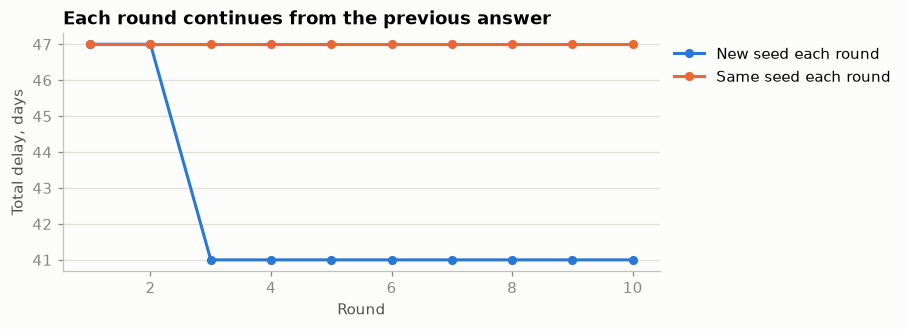

same seed: 9 of 9 restarts returned their starting plan
new seed : 8 of 9 restarts returned their starting plan


In [11]:
ROUNDS, FIRST_SEED = 10, 1


first_answer = round_solve(seed=FIRST_SEED)


def run_rounds(seed_of_round):
    solution = first_answer
    history, repeats = [-solution.score_medium], 0
    for round_number in range(1, ROUNDS):
        previous = [(a.execution_mode_id, a.delay) for a in solution.allocations]
        solution = round_solve(solution, seed=seed_of_round(round_number))
        history.append(-solution.score_medium)
        repeats += previous == [(a.execution_mode_id, a.delay) for a in solution.allocations]
    return history, repeats


same_seed, same_repeats = run_rounds(lambda round_number: FIRST_SEED)
new_seed, new_repeats = run_rounds(lambda round_number: FIRST_SEED + 10 * round_number)

fig, ax = plt.subplots(figsize=(7, 2.8))
turns = range(1, ROUNDS + 1)
ax.plot(turns, new_seed, color=COLORS[0], linewidth=2, marker="o", markersize=5, label="New seed each round")
ax.plot(turns, same_seed, color=COLORS[1], linewidth=2, marker="o", markersize=5, label="Same seed each round")
ax.set(title="Each round continues from the previous answer", xlabel="Round", ylabel="Total delay, days")
ax.grid(True, axis="y")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

print(f"same seed: {same_repeats} of {ROUNDS - 1} restarts returned their starting plan")
print(f"new seed : {new_repeats} of {ROUNDS - 1} restarts returned their starting plan")

A new seed does not guarantee progress either. A flat stretch means the search has stalled, which is
not a proof that the plan is optimal: another chain of seeds can land somewhere better.

### Add a project without moving a client's dates

Before work starts, the builder wins a fourth project, the Fire station. The Library's client has
already signed its dates, so those jobs are **pinned**: a pinned allocation keeps its mode and delay
whatever the solution says, counts in the score, and never moves. The new project's jobs are not in
the old plan, so the construction heuristic places them.

Nothing in the score rewards keeping a plan stable, so this compares three replans by the jobs they
move as well as by the delay:

- **Library pinned, old plan**: the search starts from the old plan and may move the other two projects.
- **Library pinned, no plan**: the same pins, with the other jobs placed again.
- **All old jobs pinned**: only the Fire station is open, so it has to fit around the old plan.

Library pinned, old plan : score 0 / -83 / -78, 0 jobs moved, pins kept: True
Library pinned, no plan  : score 0 / -104 / -79, 10 jobs moved, pins kept: True
All old jobs pinned      : score 0 / -83 / -78, 0 jobs moved, pins kept: True


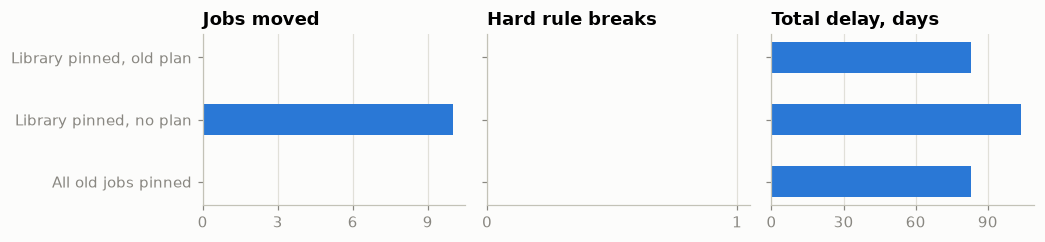

In [12]:
old = {a.id: a for _, a in working(plan)}


def replanning_problem(pinned_projects):
    schedule = make_schedule(projects=PROJECTS)
    project_of = {j.id: j.project_id for j in schedule.jobs}
    for allocation in schedule.allocations:
        if allocation.id in old and project_of[allocation.id] in pinned_projects:
            allocation.execution_mode_id = old[allocation.id].execution_mode_id
            allocation.delay = old[allocation.id].delay
            allocation.pinned = True
    return schedule


def moved_jobs(solution):
    return [a.id for _, a in working(solution) if a.id in old
            and (a.execution_mode_id, a.start_date) != (old[a.id].execution_mode_id, old[a.id].start_date)]


replans = {
    "Library pinned, old plan": pj.with_initial_solution(replanning_problem({"Library"}), plan),
    "Library pinned, no plan": replanning_problem({"Library"}),
    "All old jobs pinned": pj.with_initial_solution(replanning_problem(set(PROJECTS[:3])), plan),
}
replans = {name: best_of(schedule, seconds=0.4, seeds=range(10, 16))[0] for name, schedule in replans.items()}

for name, solution in replans.items():
    pins_held = all((a.execution_mode_id, a.start_date) == (old[a.id].execution_mode_id, old[a.id].start_date)
                    for _, a in working(solution) if a.pinned)
    print(f"{name:25}: score {solution.score_hard} / {solution.score_medium} / {solution.score_soft}, "
          f"{len(moved_jobs(solution))} jobs moved, pins kept: {pins_held}")

names = list(replans)
y = np.arange(len(names))
panels = [("Jobs moved", [len(moved_jobs(s)) for s in replans.values()]),
          ("Hard rule breaks", [-s.score_hard for s in replans.values()]),
          ("Total delay, days", [-s.score_medium for s in replans.values()])]
fig, axes = plt.subplots(1, 3, figsize=(9.6, 2.3), sharey=True)
for ax, (title, values) in zip(axes, panels):
    ax.barh(y, values, height=0.5, color=COLORS[0])
    ax.set_title(title)
    ax.set_xlim(0, max(*values, 1) * 1.05)
    ax.grid(True, axis="x")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=4))
axes[0].set_yticks(y, names)
axes[0].invert_yaxis()
plt.tight_layout()
plt.show()

If the first and third replans match, the search found nothing better than fitting the new project
around the old plan: that is the stall from section 2 again, not a proof that the plan is optimal.

Below is the first replan. Black-outlined bars are rushed or moved jobs, and the Library's rows have not
changed.

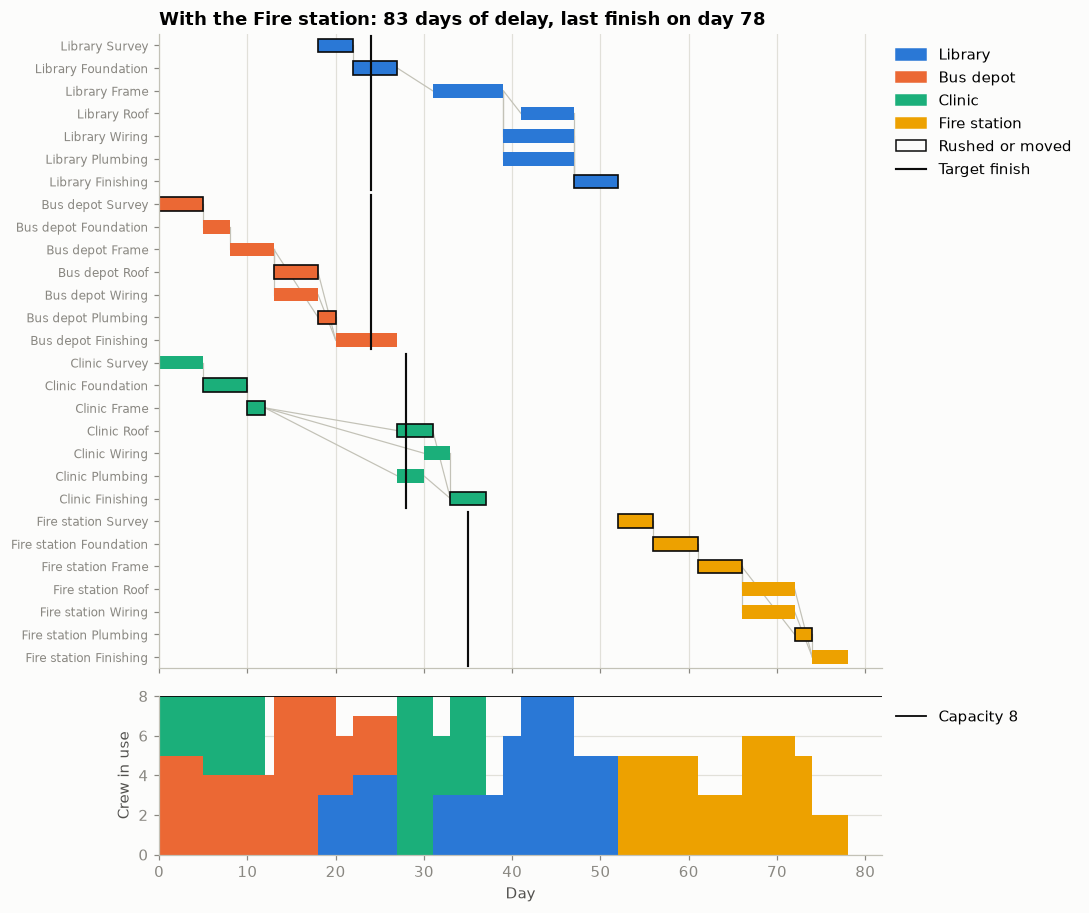

In [13]:
shown = replans["Library pinned, old plan"]
fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 8.4), sharex=True,
                                  gridspec_kw={"height_ratios": [4, 1]})
draw_gantt(top, shown, outlined=set(moved_jobs(shown)))
draw_profile(bottom, shown, CREW)
top.set_title(f"With the Fire station: {-shown.score_medium} days of delay, "
              f"last finish on day {-shown.score_soft}")
bottom.set(xlabel="Day", ylabel="Crew in use")
top.legend(handles=[*project_handles(shown),
                    Patch(facecolor="none", edgecolor="#0b0b0b", label="Rushed or moved"),
                    Line2D([], [], color="#0b0b0b", linewidth=1.4, label="Target finish")],
           loc="upper left", bbox_to_anchor=(1, 1))
bottom.legend(handles=[Line2D([], [], color="#0b0b0b", linewidth=1.2, label=f"Capacity {CREW}")],
              loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

## Next steps

- `use-cases/project-job-scheduling/README.md` covers the basic solver options and how to add your
  own moves and rules in C++.
- For one machine per job with due dates and batches, see `semiconductor-scheduling.ipynb`.